# Support Vector Machines

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC as SklearnSVC

## Maximal Margin Classifier

To understand **SVMs**, we need to first understand the **Maximal Margin Classifier**. This is an algorithm that tries to find the optimal separating hyperplane between linearly separable classes. An optimal separating hyperplane is one where the decision boundary is equidistant to the closest points in both classes and as far from both sides as possible.

<img src="https://upload.wikimedia.org/wikipedia/commons/2/20/SVM_margins.svg" width="300" height="auto">

The closest points (called *support vectors*) lie on the two lines parallel to the decision boundary, which define the margin. We can define a hyperplane (our decision boundary) as:

$$
\vec{w}\vec{x} + b = 0
$$

Any $\vec{x} = (x_1, ..., x_p)^T$ that satisfies this equation is a point on the hyperplane, the rest will fall on either side, which means the hyperplane divides the space into 2 regions. We can determine which side a point falls on by solving the equation and checking the sign of the result. In other words:

$$
\begin{align}
  \vec{w}\vec{x} + b < 0 & \text{ if $y = -1$}\\
  \vec{w}\vec{x} + b > 0 & \text{ if $y = 1$}
\end{align}
$$

Similarly, we can define the equations for the margins as:

$$
\begin{align}
  \vec{w}\vec{x} + b &= 1 \\
  \vec{w}\vec{x} + b &= -1
\end{align}
$$

In our equation of the decision boundary, $\vec{w}$ becomes the normal vector (perpendicular to the boundary), but it may not have length $1$. If we want to determine the distance (how many units we have to walk in the $\vec{w}$ direction) of a vector lying on the decision boundary to the margin defined by $\vec{w}\vec{x} + b = 1$, we solve the following equation:

$$
\vec{w}(\vec{x} + k\frac{\vec{w}}{||\vec{w}||}) + b = 1
$$

Here $\frac{\vec{w}}{||\vec{w}||}$ is a unit vector in the direction of $\vec{w}$ and $k$ is the number of units we have to walk. Solving for $k$:

$$
\begin{align}
\vec{w}\vec{x} + \vec{w}k\frac{\vec{w}}{||\vec{w}||} + b = 1 \\
\vec{w}\vec{x} + k\frac{||\vec{w}||^2}{||\vec{w}||} + b = 1 \\
\vec{w}\vec{x} + k||\vec{w}|| + b = 1 \\
k||\vec{w}|| = 1 - (\vec{w}\vec{x} + b)
\end{align}
$$

Since $\vec{w}\vec{x} + b = 0$, we get:

$$
\begin{align}
k||\vec{w}|| = 1 \\
k = \frac{1}{||\vec{w}||}
\end{align}
$$

This tells us that the size of the margin is $\frac{2}{||\vec{w}||}$. This means we need to minimize $||\vec{w}||$ in order to maximize the margin. In order for us to obtain the correct solution, we need to put a constraint in, the constraint being that we want to classify the points correctly depending on which side of the margin they fall on:

$$
\begin{align}
y^{(i)} = 1 \Rightarrow \vec{w}\vec{x^{(i)}} + b \ge 1 \\
y^{(i)} = -1 \Rightarrow \vec{w}\vec{x^{(i)}} + b \le 1
\end{align}
$$

This reduces to

$$
y^{(i)}(\vec{w}\vec{x^{(i)}} + b) \ge 1
$$

This also tells us that the support vectors satisfy the following:

$$
y^{(i)}(\vec{w}\vec{x^{(i)}} + b) = 1
$$

So for a **Maximum Margin Classifier** (*Hard Margin SVM*), we get the following objective:

$$
\underset{\vec{w},b}{\min} ||\vec{w}||
$$

such that

$$
y_i(\vec{w}\vec{x^{(i)}} + b) \ge 1 ~\forall i = 1, ..., N
$$

where $N$ is the number of samples.

## Support Vector Machine

**Maximum Margin Classifiers** impose the requirement that the data be linearly separable, otherwise we wouldn't be able to establish the decision boundary and the margin. This limits their usefulness in real life scenarios where data is rarely linearly separable. **SVMs** address this issue by allowing some points to violate the margin or even the decision boundary (which is why we also call them *Soft Margin SVMs*).

<img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*RgFWpCEG5AvnmGF5ESy1Tg.png" width="600" height="auto"/>

To classify the points correctly, we will use the **Hinge Loss**:

$$
L = \max(0, 1 - y_i(\vec{w}\vec{x^{(i)}} + b))
$$

The Hinge Loss will be $0$ for correctly classified samples that are outside of the margin. For correctly classified samples inside the margin, there will be a small penalty, but the penalty will increase rapidly if the sample is incorrectly classified and on the wrong side of the margin.

<img src="https://media.geeksforgeeks.org/wp-content/uploads/20231104124004/1.png" width="500" height="auto"/>

The Soft Margin SVM model then becomes:

$$
\underset{\vec{w},b}{\min} \left( \frac{1}{2} ||\vec{w}||^2 + C \sum_{i=1}^N \max (0, 1 - y^{(i)}(\vec{w}\vec{x^{(i)}} + b)) \right)
$$

The first term maximizes the margin such that no point gets misclassified. We square the size of the margin to make the math easier. The second term is the Hinge loss and it allows for some slack in the hard margin, letting some points violate it. The parameter $C$ controls how much slack we allow, and thus how many points are allowed to violate the margin. This also means that with more slack, the margin gets wider. We find that:

$$
\xi^{(i)} = \max (0, 1 - y^{(i)}(\vec{w}\vec{x^{(i)}} + b))
$$

where $\xi^{(i)}$ is the slack variable for sample $i$ and it's defined as the Hinge loss. This means that:

$$
\begin{align}
\text{if } y^{(i)}(\vec{w}\vec{x^{(i)}} + b) \ge 1 & \Rightarrow \xi^{(i)} = 0 \\
\text{if } y^{(i)}(\vec{w}\vec{x^{(i)}} + b) < 1 & \Rightarrow \xi^{(i)} = 1 - y^{(i)}(\vec{w}\vec{x^{(i)}} + b)
\end{align}
$$

This basically tells us that if a point is on the correct side of the margin, we don't need any slack, so we set it to $0$, whereas if it violates the margin, we need to allow some slack which is proportional to how far it's on the wrong side of the margin.

Since we've established our objective, we can use **Gradient Descent** to find the minimum of our cost function $J(\vec{w}, b) = \frac{1}{2} ||\vec{w}||^2 + C \sum_{i=1}^N \max (0, 1 - y^{(i)}(\vec{w}\vec{x^{(i)}} + b))$. We iteratively update:

$$
\begin{align}
w_j & \leftarrow w_j - \eta \frac{\partial{J}}{\partial{w_j}} \text{ for } j = 1, ..., m \\
b & \leftarrow b - \eta \frac{\partial{J}}{\partial{b}}
\end{align}
$$

where $m$ is the number of features/dimensions. We compute the derivatives:

$$
\begin{align}
\frac{\partial{J}}{\partial{w_j}} & = w_j - C \sum_{i=1}^m
\begin{cases}
0 & \text{ if loss} = 0,\\
y^{(i)} x_j^{(i)} & \text{ otherwise}
\end{cases} \\
\frac{\partial{J}}{\partial{b}} & = - C \sum_{i=1}^m
\begin{cases}
0 & \text{ if loss} = 0,\\
y^{(i)} & \text{ otherwise}
\end{cases}
\end{align}
$$

where $w_j$ is the the weight for feature $j$. We can thus rewrite our Gradient Descent step as:

$$
\begin{align}
w_j & \leftarrow w_j - \eta \left [w_j - C \sum_{i=1}^m I (1 - y^{(i)}(\vec{w}\vec{x^{(i)}} + b) > 0) y^{(i)} x^{(i)} \right] \\
b_j & \leftarrow b_j - \eta \left [- C \sum_{i=1}^m I (1 - y^{(i)}(\vec{w}\vec{x^{(i)}} + b) > 0) y^{(i)} \right]
\end{align}
$$

Where $I$ is an indicator function.

### Dual Form

The above cost function $J$ is the so-called **primal form** of the optimization problem. This is fine for linear problems, but **SVMs** can also be used on non-linear problems by using the **kernel trick**. This means substituting certain parts of the cost function with different computations, making the algorithm incredibly flexible. To be able to perform this substitution, we have to express the optimization problem in its **dual form**.

In order to be able to do this, we have to take a brief detour and talk about Lagrange Multipliers.

### Lagrange Multipliers

**Lagrange Multipliers** are a method of finding the minimum or maximum of a function subject to some constraint. In other words, we want to optimize $f(x, y)$, but $x$ and $y$ cannot be chosen freely and must obey some constraint (e.g. $g(x, y) = 0$). At the optimal point, the gradients of $f$ and $g$ point in the same directions and are just scalar multiples of one another. That means that we can set:

$$
\nabla f(x, y) = \lambda \nabla g(x, y)
$$

We then want to solve for $x$, $y$ and $\lambda$.

#### Example

Find the maximum and minimum of

$$
f(x, y) = xy
$$

subject to

$$
x^2 + y^2 = 1
$$

i.e. find the maximum and minimum among the points on the circle.

<img src="lagrange.png" width="500" height="auto"/>

We rewrite the constraint and introduce $\lambda$, manipulating the constraint such that it evaluates to $0$:

$$
L(x, y, \lambda) = xy + \lambda (1 - x^2 - y^2)
$$

Then take partial derivatives and set them to $0$, treating $\lambda$ as just another constant:

$$
\begin{align}
\frac{\partial{L}}{\partial{x}} & = y - 2 \lambda x = 0 \\
\frac{\partial{L}}{\partial{y}} & = x - 2 \lambda y = 0 \\
\frac{\partial{L}}{\partial{\lambda}} & = 1 - x^2 - y^2 = 0
\end{align}
$$

We solve for the unknown variables:

$$
\begin{align}
x &= 2 \lambda y \\
y &= 2 \lambda x \\
y &= 2 \lambda(2 \lambda y) = 4 \lambda^2 y
\end{align}
$$

If $y \neq 0$, then $4 \lambda^2 = 1 \Rightarrow \lambda = \pm \frac{1}{2}$.

Plugging back in:
- For $\lambda = \frac{1}{2}: y = x$
- For $\lambda = -\frac{1}{2}: y = -x$

Using the constraint $x^2 + y^2 = 1$:
- If $y = x: 2x^2 = 1 \Rightarrow x = \pm \frac{1}{\sqrt{2}}, y = \pm \frac{1}{\sqrt{2}}$
- If $y = -x: 2x^2 = 1 \Rightarrow x = \pm \frac{1}{\sqrt{2}}, y = \pm \frac{1}{\sqrt{2}}$

Evaluating $f(x, y)$, we find:
- For $y = x: f = x^2 = \frac{1}{2} \rightarrow \text{maximum}$
- For $y = -x: f = -x^2 = -\frac{1}{2} \rightarrow \text{minimum}$

That means we achieve the maximum value $\frac{1}{2}$ at $(\frac{1}{\sqrt{2}}, \frac{1}{\sqrt{2}})$ and $(-\frac{1}{\sqrt{2}}, -\frac{1}{\sqrt{2}})$ and the minimum value $-\frac{1}{2}$ at $(\frac{1}{\sqrt{2}}, -\frac{1}{\sqrt{2}})$ and $(-\frac{1}{\sqrt{2}}, \frac{1}{\sqrt{2}})$.

### Finding the Dual Form

We can use the same strategy to derive an alternative form of the cost function using Lagrange multipliers. Remember our cost function and our 2 constraints in the primal form:

$$
\begin{align}
J = \frac{1}{2} ||\vec{w}||^2 + C \sum_{i=1}^N \xi^{(i)} \\
\text{such that} \\
y^{(i)}(\vec{w}\vec{x}^{(i)} + b) + \xi^{(i)} \ge 1 ~ \forall i \\
\xi^{(i)} \ge 0 ~ \forall i
\end{align}
$$

We rewrite this as a Lagrangian, introducing a new variable for each constraint:

$$
L(\vec{w}, b, \vec{\xi}, \vec{\alpha}, \vec{\beta}) = \frac{1}{2} ||\vec{w}||^2 + C \sum_{i=1}^N \xi^{(i)} + \sum_{i=1}^N \alpha^{(i)}(1- y^{(i)}(\vec{w}\vec{x}^{(i)} + b) - \xi^{(i)}) + \sum_{i=1}^N \beta^{(i)}(-\xi^{(i)})
$$

Our Dual problem becomes:

$$
\underset{\vec{w},b}\min \left[ \underset{\alpha \ge 0, \beta \ge 0}\max L(\vec{w}, b, \vec{\xi}, \vec{\alpha}, \vec{\beta}) \right] = \underset{\alpha \ge 0, \beta \ge 0}\max \left[ \underset{\vec{w},b}\min L(\vec{w}, b, \vec{\xi}, \vec{\alpha}, \vec{\beta}) \right]
$$

We want to minimize the above with respect to $\vec{w}$, $b$ and $\vec{\xi}$, which means taking the derivative and setting it to $0$:

$$
\begin{align}
\frac{\partial{L}}{\partial{\vec{w}}} &= \vec{w} - \sum_{i=1}^N \alpha^{(i)} x^{(i)} y^{(i)} = 0 \\
&\Rightarrow \vec{w} = \sum_{i=1}^N \alpha^{(i)} x^{(i)} y^{(i)}
\end{align}
$$

$$
\begin{align}
\frac{\partial{L}}{\partial{b}} &= - \sum_{i=1}^N \alpha^{(i)} y^{(i)} = 0 \\
&\Rightarrow \sum_{i=1}^N \alpha^{(i)} y^{(i)} = 0
\end{align}
$$

$$
\begin{align}
\frac{\partial{L}}{\partial{\vec{\xi^{(i)}}}} &= C - \alpha^{(i)} - \beta^{(i)} = 0 \\
&\Rightarrow \alpha^{(i)} + \beta^{(i)} = C ~ \forall i
\end{align}
$$

We substitute this back into the Lagrangian:

$$
L = \frac{1}{2} \left( (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \cdot (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \right) + C \sum_{i=1}^N \xi^{(i)} + \sum_{i=1}^N \alpha^{(i)} - \left( (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \cdot (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \right) - b\sum_{i=1}^N \alpha^{(i)} y^{(i)} - \sum_{i=1}^N \alpha^{(i)} y^{(i)}
$$

The dot products in the first and fourth term are the same, so we subtract. In addition, we've established that $\sum_{i=1}^N \alpha^{(i)} y^{(i)} = 0$, so those terms go away, leaving us with:

$$
L = \sum_{i=1}^N \alpha^{(i)} -\frac{1}{2} \left( (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \cdot (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \right) + C \sum_{i=1}^N \xi^{(i)}
$$

The last term can be expanded:

$$
C \sum_{i=1}^N \xi^{(i)} = \sum_{i=1}^N \xi^{(i)} (C - \alpha^{(i)} - \beta^{(i)})
$$

Since $C = \alpha^{(i)} + \beta^{(i)} ~ \forall i$, we get

$$
\sum_{i=1}^N \xi^{(i)} (C - \alpha^{(i)} - \beta^{(i)}) = \sum_{i=1}^N \xi^{(i)} (\alpha^{(i)} + \beta^{(i)} - \alpha^{(i)} - \beta^{(i)}) = 0
$$

Our final Lagrangian thus reduces to

$$
\begin{align}
L & = \sum_{i=1}^N \alpha^{(i)} -\frac{1}{2} \left( (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \cdot (\sum_{i=1}^N \alpha^{(i)} y^{(i)} x^{(i)}) \right) \\
& = \sum_{i=1}^N \alpha^{(i)} - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha^{(i)} \alpha^{(j)} y^{(i)} y^{(j)} x^{(i)T} x^{(j)}
\end{align}
$$

which is what we want to maximize.

### Kernel Functions

This **dual formulation** is also kernel-friendly. It shows that for a linear SVM, the output is dependent on dot products of $x^{(i)}$ and $x^{(j)}$. If we want to then model non-linearities, all we need to do is replace the dot product with a function that maps the space where the $x^{(i)}$'s live to some other space where the boundary between them is again linear.

<img src="https://upload.wikimedia.org/wikipedia/commons/c/cc/Kernel_trick_idea.svg" width="600" height="auto"/>

The important part is that we can find a function (so-called **kernel function**) that takes the dot products themselves and transform them, as opposed to transforming each of the $x^{(i)}$, which offers large computational advantages. We already know the linear kernel function:

$$
K(x^{(i)}, x^{(j)}) = x^{(i)} \cdot x^{(j)}
$$

There are other useful kernels, such as the **polynomial kernel**:

$$
K_{poly(d)}(x^{(i)}, x^{(j)}) = (x^{(i)} \cdot x^{(j)} + c)^d
$$

where $c$ is controls the effect of the higher-order and lower-order terms and $d$ is the degree of the polynomial. This allows us to capture non-linear relationships by expanding the original feature space with polynomial and interaction terms. For example, for two 2D vectors $x^{(i)}, x^{(j)}$, $c=1$ and $d=2$, we get:

$$
\begin{align}
K_{poly(2)}(x^{(i)}, x^{(j)})  &= (x_1^{(i)}x_1^{(j)} + x_2^{(i)}x_2^{(j)} + 1)^2 \\
&= (x_1^{(i)}x_1^{(j)})^2 + (x_2^{(i)}x_2^{(j)})^2 + 2x_1^{(i)}x_1^{(j)}x_2^{(i)}x_2^{(j)} + 2x_1^{(i)}x_1^{(j)} + 2x_2^{(i)}x_2^{(j)} + 1
\end{align}
$$

This shows that the kernel implicitly considers all quadratic combinations of the features, without computing them explicitly.

Another useful kernel is the **radial basis function kernel**. This kernel is capable of taking into account very non-linear decision boundaries that are beyond quadratic or polynomial. This is achieved by projecting the original data into an infinite-dimensional space, taking into consideration all the infinite interactions of the different degree terms. The kernel is defined as:

$$
\begin{align}
K_{rbf}(x^{(i)}, x^{(j)}) &= e^{-\frac{1}{2}||x^{(i)}-x^{(j)}||^2} \\
&= e^{-\frac{1}{2}[(x^{(i)} - x^{(j)})^T (x^{(i)} - x^{(j)})]} \\
&= e^{-\frac{1}{2}[x^{(i)T}x^{(i)} - 2x^{(i)T}x^{(j)} + x^{(j)T}x^{(j)}]} \\
&= e^{-\frac{1}{2}[x^{(i)T}x^{(i)} + x^{(j)T}x^{(j)}]} e^{x^{(i)T}x^{(j)}}
\end{align}
$$

This shows that we can express the kernel function in terms of the dot products. We can further manipulate this:

$$
\begin{align}
K_{rbf}(x^{(i)}, x^{(j)}) &= C e^{x^{(i)T}x^{(j)}} \text{ where } C = e^{-\frac{1}{2}[x^{(i)T}x^{(i)} + x^{(j)T}x^{(j)}]} \\
&= C e^{x^{(i)T}x^{(j)} + 1} e^{-1} \\
&= C' e^{x^{(i)T}x^{(j)} + 1} \text{ where C' absorbs } e^{-1} \\
&= C' \sum_{n=1}^\infty \frac{(1 + x^{(i)T}x^{(j)})^n}{n!} \text{ (definition of e as an infinite sum)} \\
&= C' \sum_{n=1}^\infty \frac{K_{poly(n)}(x^{(i)}, x^{(j)})}{n!}
\end{align}
$$

This shows that the RBF kernel considers all infinite interactions between our original data.

We can simply plug the desired kernel function into our Lagrangian:

$$
L = \sum_{i=1}^N \alpha^{(i)} - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha^{(i)} \alpha^{(j)} y^{(i)} y^{(j)} K(x^{(i)}, x^{(j)})
$$

### Optimization

We can now restate the objective as:

$$
\begin{align}
\underset{\vec{\alpha}}\max (L) = \underset{\vec{\alpha}}\max \sum_{i=1}^N \alpha^{(i)} - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha^{(i)} \alpha^{(j)} y^{(i)} y^{(j)} K(x^{(i)}, x^{(j)}) \\
\text{subject to } 0 \le \alpha^{(i)} \le, \sum_{i=1}^N \alpha^{(i)} = 0
\end{align}
$$

Using Gradient Descent in this setting risks violating the constraints and would require us to repeatedly project into the feasable region, which leads to slow convergence and brittle optimization, that's highly sensitive to the choice of learning rate. The optimal $\alpha^{(i)}$ must satisfy the **Krush-Kuhn-Tucker (KKT)** conditions:

$$
\alpha^{(i)}[y^{(i)}(w \cdot x^{(i)} + b) - 1] = 0
$$

which Gradient Descent doesn't enforce. To circumvent this problem, specialized algorithms like **Sequential Minimal Optimization (SMO)** were developed. SMO works by breaking down the optimization problem into the smalles possible subproblems and solving each one analytically. Each turn, we select two parameters $\alpha^{(i)}, \alpha^{(j)}$ and update them such that the constraints are maintained. The outline of the algorithm is as follows:

At each iteration:
1. Choose two parameters $\alpha^{(i)}, \alpha^{(j)}$
    - One is chosen because it violates the KKT conditions, meaning it's not optimal
    - The other is chosen heuristically (to speed up convergence) or at random, making sure that $i \neq j$
2. Compute the bounds $L$ and $H$ for the new values of $\alpha^{(j)}$
    - These come from the box constraints $0 \le \alpha^{(i)}, \alpha^{(j)} \le C$
    - The new pair $(\alpha'^{(i)}, \alpha'^{(j)})$ must lie in this range
3. Compute the optimal update analytically
    - When we treat all other $\alpha^{(k)}$ as fixed, this becomes a simple quadratic function in $\alpha^{(j)}$
    - We find the maximum by taking the derivative and solving explicitly
4. Clip the result to satisfy the box constraints ($L \le \alpha^{(i)} \le H$)
5. Update $\alpha^{(i)}$ accordingly, so the constraints hold
6. Update the bias term $b$ to reflect the new support vectors
7. Repeat until all $\alpha^{(i)}$ satisfy the KKT conditions within some tolerance

In practice, after we've chose the indices $i$ and $j$, we compute:

$$
f(x) = \sum_{i=1}^N \alpha^{(i)} y^{(i)} K(x^{(i)}, x) + b
$$

Compute error:
$$
E^{(i)} = f^{(i)} - y^{(i)}
$$

Compute upped and lower bounds:
$$
L = max(0, \alpha^{(j)} - \alpha^{(i)}), H = min(C, C + \alpha^{(j)} - \alpha^{(i)}) ~ \text{ if } ~ y^{(i)} \neq y^{(j)}
$$

$$
L = max(0, \alpha^{(i)} + \alpha^{(j)} - C), H = min(C, \alpha^{(i)} + \alpha^{(i)}) ~ \text{ otherwise}
$$

Compute new $\alpha^{(j)}$:
$$
\alpha^{(j)} := \alpha^{(j)} - \frac{y^{(j)} (E^{(i)} - E^{(j)})} {\eta}
$$

where:

$$
\eta = K(x^{(i)}, x^{(i)}) + K(x^{(j)}, x^{(j)}) - 2K(x^{(i)}, x^{(j)}) \ge 0
$$

Then clip the new $\alpha^{(j)}$:
$$
\alpha^{(j)} = \begin{cases}
H \text{ if } \alpha^{(j)} > H \\
L \text { if } \alpha^{(j)} < L \\
\alpha^{(j)} \text{ otherwise}
\end{cases}
$$

Update $\alpha^{(i)}$ from the new $\alpha^{(j)}$:
$$
\alpha^{(i)} := \alpha^{(i)} + y^{(i)} y^{(j)} (\alpha_{old}^{(j)} - \alpha^{(j)})
$$

Then compute the intercept value $b$:
$$
\begin{align}
b_1 &= b - E^{(i)} - y^{(i)} (\alpha^{(i)} - \alpha_{old}^{(i)})K(x^{(i)}, x^{(i)}) - y^{(j)} (\alpha^{(j)} - \alpha_{old}^{(j)})K(x^{(i)}, x^{(j)}) \\
b_2 &= b - E^{(j)} - y^{(i)} (\alpha^{(i)} - \alpha_{old}^{(i)})K(x^{(i)}, x^{(j)}) - y^{(j)} (\alpha^{(j)} - \alpha_{old}^{(j)})K(x^{(j)}, x^{(j)}) \\
b &:= \begin{cases}
b_1 & \text{ if } 0 < \alpha^{(i)} < C \\
b_2 & \text{ if } 0 < \alpha^{(j)} < C \\
(b_1 + b_2)/2 & \text{ otherwise}
\end{cases}
\end{align}
$$

<hr/>

**Sources**:

[SVM (The Math) : Data Science Concepts](https://www.youtube.com/watch?v=bM4_AstaBZo)

[Soft Margin SVM : Data Science Concepts](https://www.youtube.com/watch?v=IjSfa7Q8ngs)

[SVM Dual : Data Science Concepts](https://www.youtube.com/watch?v=6-ntMIaJpm0)

[SVM Kernels : Data Science Concepts](https://www.youtube.com/watch?v=OKFMZQyDROI)

[Radial Basis Function Kernel : Data Science Concepts](https://www.youtube.com/watch?v=Q0ExqOphnW0)

[MIT OpenCourseWare: Support Vector Machines](https://www.youtube.com/watch?v=_PwhiWxHK8o)

[Support Vector Machine (SVM) from Scratch](https://www.youtube.com/watch?v=qiLzuaXIBb8)

[Dual formulation for Soft Margin SVM](https://www.youtube.com/watch?v=MZzp4OP8GgQ)

[Machine Learning 41: Support Vector Machines - SMO Algorithm](https://www.youtube.com/watch?v=Mfp7HQKLSAo)

[Soft Margin SVM](https://pages.hmc.edu/ruye/MachineLearning/lectures/ch9/node8.html)

[Sequential Minimal Optimization (SMO) Algorithm](https://pages.hmc.edu/ruye/MachineLearning/lectures/ch9/node9.html)

[The Simplified SMO Algorithm](https://cs229.stanford.edu/materials/smo.pdf)

In [4]:
from sklearn.base import BaseEstimator, ClassifierMixin

class SVC(BaseEstimator, ClassifierMixin):
    def __init__(self, kernel='linear', C=1., degree=None, tol=1e-5, eps=1e-10,
                 max_iter=1000, coef0=0., gamma='scale'):
        assert kernel in ('linear', 'poly', 'rbf')
        assert C > 0
        if kernel == 'poly':
            assert degree is not None
            assert coef0 is not None
        if gamma not in ('scale', 'auto'):
            assert gamma > 0
        
        self.kernel = kernel
        self.C = C
        self.degree = degree
        self.gamma = gamma
        self.tol = tol
        self.eps = eps
        self.max_iter = max_iter
        self.coef0 = coef0
        self.intercept = None
        self.coefs = None
        self.alphas = None
        self.support_ = None
        self.support_vectors_ = None
        self.support_labels_ = None

    def fit(self, X, y):
        assert len(np.unique(y)) == 2
        # convert labels to -1, 1
        y = np.where(y == 0, -1, 1)
        n_samples, n_features = X.shape
        # compute gamma value
        if self.gamma == 'scale':
            self.gamma = 1 / (n_features * X.var())
        elif self.gamma == 'auto':
            self.gamma = 1 / n_features
        # initialize vector of alphas to all 0
        # this satisfies both constraints
        alphas = np.zeros(n_samples)
        # initialize bias term
        b = 0.
        # precompute the Gram matrix
        K = self._compute_gram(X, X.T)

        n_passes = 0
        while n_passes < self.max_iter:
            n_changed_alphas = 0
            # randomize to improve convergence
            for i in np.random.permutation(n_samples):
                f_i = (alphas * y) @ K[i] + b
                y_f = y[i] * f_i

                # check KKT conditions violation
                if not (
                    (y_f < 1 - self.tol and alphas[i] < self.C) or
                    (y_f > 1 + self.tol and alphas[i] > 0)
                ):
                    continue

                # compute error
                E_i = f_i - y[i]
                # select j != i
                j = np.random.choice([x for x in range(n_samples) if x != i])
                f_j = (alphas * y) @ K[j] + b
                E_j = f_j - y[j]
                # store old alpha values
                alpha_i_old = alphas[i]
                alpha_j_old = alphas[j]
                
                # compute lower and upper bound
                if y[i] == y[j]:
                    L = max(0, alpha_i_old + alpha_j_old - self.C)
                    H = min(self.C, alpha_i_old + alpha_j_old)
                else:
                    L = max(0, alpha_j_old - alpha_i_old)
                    H = min(self.C, self.C + alpha_j_old - alpha_i_old)
                # guard against degenerate case
                if L == H:
                    continue
                
                # compute eta
                eta = K[i, i] + K[j, j] - 2 * K[i, j]
                # guard against degenerate case
                if eta <= 0:
                    continue
                
                # update alpha_j
                alphas[j] = alpha_j_old + y[j] * (E_i - E_j) / eta
                alphas[j] = np.clip(alphas[j], L, H)

                if np.abs(alphas[j] - alpha_j_old) < self.tol:
                    continue

                # update alpha_i
                alphas[i] = alpha_i_old + y[i] * y[j] * (alpha_j_old - alphas[j])

                # update bias
                b_1 = b - E_i - y[i] * (alphas[i] - alpha_i_old) * K[i, i] - y[j] * (alphas[j] - alpha_j_old) * K[i, j]
                b_2 = b - E_j - y[i] * (alphas[i] - alpha_i_old) * K[i, j] - y[j] * (alphas[j] - alpha_j_old) * K[j, j]

                if 0 < alphas[i] < self.C:
                    b = b_1
                elif 0 < alphas[j] < self.C:
                    b = b_2
                else:
                    b = (b_1 + b_2) / 2
                n_changed_alphas += 1
            
            if n_changed_alphas == 0:
                n_passes += 1
            else:
                n_passes = 0
        
        self.intercept = b
        self.alphas = alphas
        self.support_ = self.alphas > self.eps
        self.support_vectors_ = X[self.support_]
        self.support_labels_ = y[self.support_]
        # recover the linear coefficients if the kernel is linear
        if self.kernel == 'linear':
            w = self.alphas * y @ X
            self.coefs = w
        
        return self

    def predict(self, X):
        preds = self.decision_function(X)
        return np.where(preds >= 0, 1, 0)

    def decision_function(self, X):
        sv_alphas = self.alphas[self.support_]
        sv_labels = self.support_labels_
        sv_vectors = self.support_vectors_
        K = self._compute_gram(sv_vectors, X.T)
        decision = (sv_alphas * sv_labels) @ K + self.intercept
        return decision

    def _compute_gram(self, X1, X2):
        if self.kernel == 'linear':
            return self._linear(X1, X2)
        elif self.kernel == 'poly':
            return self._poly(X1, X2)
        elif self.kernel == 'rbf':
            return self._rbf(X1, X2)
        
    def _linear(self, X1, X2):
        return np.dot(X1, X2)

    def _poly(self, X1, X2):
        return (self.gamma * np.dot(X1, X2) + self.coef0) ** self.degree

    def _rbf(self, X1, X2):
        X = X1[:, np.newaxis] - X2.T[np.newaxis, :]
        norm_sq = np.linalg.norm(X, 2, axis=2) ** 2
        return np.exp(-self.gamma * norm_sq)

In [6]:
X = np.array(
    [
        [0.4, -0.7],
        [-1.5, -1.0],
        [-1.4, -0.9],
        [-1.3, -1.2],
        [-1.1, -0.2],
        [-1.2, -0.4],
        [-0.5, 1.2],
        [-1.5, 2.1],
        [1.0, 1.0],
        [1.3, 0.8],
        [1.2, 0.5],
        [0.2, -2.0],
        [0.5, -2.4],
        [0.2, -2.3],
        [0.0, -2.7],
        [1.3, 2.1],
    ]
)
y = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])

In [10]:
svc = SVC(kernel='linear').fit(X, y)
svc.coefs, svc.intercept

(array([ 1.28514056, -0.3480589 ]), np.float64(0.06022056540792669))

In [11]:
sklearn_svc = SklearnSVC(kernel='linear').fit(X, y)
sklearn_svc.coef_, sklearn_svc.intercept_

(array([[ 1.28464065, -0.34792353]]), array([0.06034725]))

In [12]:
svc.support_vectors_

array([[ 0.4, -0.7],
       [-0.5,  1.2],
       [ 1. ,  1. ],
       [ 0. , -2.7],
       [ 1.3,  2.1]])

In [13]:
sklearn_svc.support_vectors_

array([[ 0.4, -0.7],
       [-0.5,  1.2],
       [ 1. ,  1. ],
       [ 0. , -2.7],
       [ 1.3,  2.1]])

In [14]:
def plot_training_data_with_decision_boundary(clf, X, y, support_vectors=True):
    # Create plot
    fig, ax = plt.subplots(figsize=(4, 3))
    x_min, x_max, y_min, y_max = -3, 3, -3, 3
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

    # Create a dense mesh grid
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Get decision values for the grid
    Z = clf.decision_function(grid)
    Z = Z.reshape(xx.shape)

    # Plot filled decision regions
    region_pred = clf.predict(grid)
    region_pred = region_pred.reshape(xx.shape)
    ax.pcolormesh(xx, yy, region_pred, shading='auto', alpha=0.3, cmap=plt.cm.coolwarm)

    # Plot decision boundary and margins
    ax.contour(
        xx, yy, Z,
        levels=[-1, 0, 1],
        colors=["k", "k", "k"],
        linestyles=["--", "-", "--"]
    )

    # Highlight support vectors
    if support_vectors and hasattr(clf, "support_vectors_"):
        ax.scatter(
            clf.support_vectors_[:, 0],
            clf.support_vectors_[:, 1],
            s=150,
            facecolors='none',
            edgecolors='k',
            linewidths=1.5,
            label='Support Vectors'
        )

    # Plot training data points
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors="k", cmap=plt.cm.coolwarm)
    ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
    ax.set_title(f"Decision boundaries of {clf.kernel} kernel in SVC")

    plt.show()

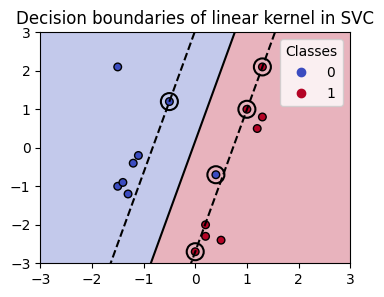

In [15]:
plot_training_data_with_decision_boundary(
    SVC(kernel='linear', gamma=2).fit(X, y), X, y
)

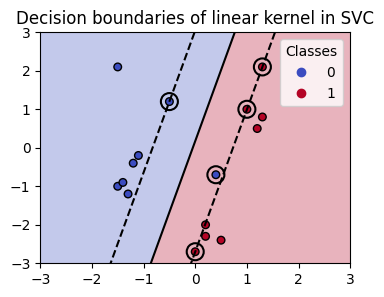

In [16]:
plot_training_data_with_decision_boundary(
    SklearnSVC(kernel='linear', gamma=2).fit(X, y), X, y
)

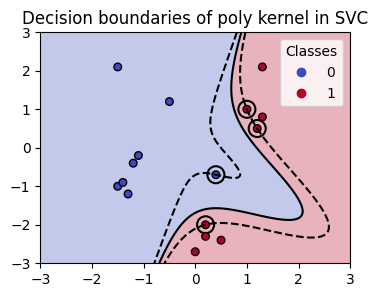

In [17]:
plot_training_data_with_decision_boundary(
    SVC(kernel='poly', degree=3, gamma=2).fit(X, y), X, y
)

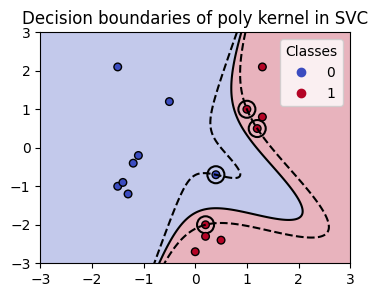

In [18]:
plot_training_data_with_decision_boundary(
    SklearnSVC(kernel='poly', degree=3, gamma=2).fit(X, y), X, y
)

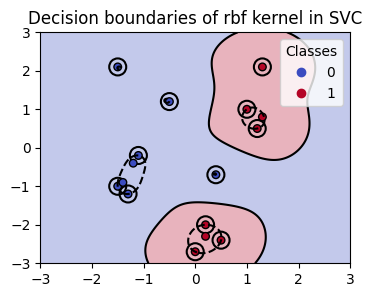

In [19]:
plot_training_data_with_decision_boundary(
    SVC(kernel='rbf', gamma=2).fit(X, y), X, y
)

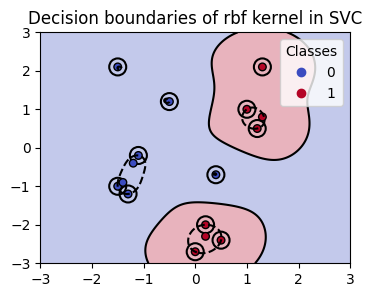

In [20]:
plot_training_data_with_decision_boundary(
    SklearnSVC(kernel='rbf', gamma=2).fit(X, y), X, y
)